# Tutorial 1: Quick start with the example data

This tutorial takes you through a complete meltinv analysis of the bundled example file, **`examples.xlsx`**: 38 basalts from five Austral–Cook islands (Mangaia, Raivavae, Rapa, Atiu and Marotiri). It takes about a minute to run.

### Two kinds of cell

| Cell starts with | What it does | Needed for your own analysis? |
|---|---|---|
| `# ▶ meltinv` | Reads your input or runs meltinv: the analysis itself | **Yes**. These are the only steps you need |
| `# (optional)` | Reads the result files or makes plots, to show what meltinv did | No. Only for looking at the results |

The whole analysis is just these lines (the same as in the main [README](../README.md)):

```python
import meltinv
import pandas as pd

data = pd.read_excel("examples.xlsx")                                 # 0. read your input file
meltinv.correction("examples.xlsx")                                   # 1. olivine correction
meltinv.invert("inversion_results/examples_corrected.xlsx",           # 2. inversion
               individual_sample_figures=True)
```

Everything else in this notebook helps you understand the inputs and outputs.

**Before you start:** install meltinv and open this notebook as described in the [tutorials README](README.md).

## 0. Setup

In [1]:
# ▶ meltinv: import meltinv and work in a folder that contains your input file
import os
import shutil
import sys
from pathlib import Path

import pandas as pd

try:
    import meltinv
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "meltinv is not installed in the Python that runs this notebook.\n"
        "Fix: in JupyterLab choose Kernel > Change Kernel > 'Python (meltinv)', or close JupyterLab and start it\n"
        "again with the Python where meltinv is installed, e.g. from the tutorials folder:\n"
        "    ../venv/bin/python -m jupyterlab\n"
        "(see tutorials/README.md)") from None

# meltinv writes its results to the current folder. For this tutorial we copy examples.xlsx into
# tutorials/output/01_quick_start/ and work there, so nothing is written into the rest of the repository.
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples.xlsx").exists())
work = repo / "tutorials" / "output" / "01_quick_start"
work.mkdir(parents=True, exist_ok=True)
shutil.copy(repo / "examples.xlsx", work / "examples.xlsx")
os.chdir(work)
print(f"meltinv {meltinv.__version__}, Python {sys.version.split()[0]}")

meltinv 0.1.0, Python 3.11.15


In [2]:
# (optional) tools for reading the result files and making plots
import io

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from PIL import Image as PILImage

from meltinv.plot_ree import plot_ree

REE = ['La', 'Ce', 'Pr', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu']
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # one colour per island


def show_log(captured, starts=("Skipping", "Results saved", "Converted")):
    # Print only the useful lines of meltinv's progress log (hidden with %%capture)
    for line in captured.stdout.splitlines():
        if line.startswith(starts):
            print(line.replace(str(Path.cwd()) + "/", ""))
    for line in captured.stderr.splitlines():
        if "RuntimeWarning:" in line:
            print("Warning:", line.split("RuntimeWarning:", 1)[1].strip())


def show_png(path, width=900):
    # Display a saved figure, downsized so the notebook stays small
    img = PILImage.open(path)
    img.thumbnail((1300, 1300))
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    display(Image(data=buf.getvalue(), width=width))

## 1. Look at the input data

meltinv reads an `.xlsx` or `.csv` file with **one row per sample**. Only a few columns are needed:

| Column | Needed for | Meaning |
|---|---|---|
| `location` | always | Samples with the same location are summarised and plotted together |
| `La` … `Lu` (14 REE) | always | REE concentrations in ppm |
| `SiO2` … `P2O5` (10 oxides) | the olivine correction | Major elements in wt% |
| `thickness` | optional | An independent lithospheric thickness (km), e.g. from seismology. Used only for comparison |

Any other columns are carried through to the outputs. First, read the input file:

In [3]:
# ▶ meltinv input: read your input file
data = pd.read_excel("examples.xlsx")

In [4]:
# (optional) count the samples at each location
print(f"{len(data)} samples, {data.shape[1]} columns")
data.groupby("location").size().rename("samples").to_frame()

38 samples, 174 columns


,samples
location,
Austral-Cook Islands (Atiu),3
Austral-Cook Islands (Mangaia),14
Austral-Cook Islands (Marotiri),1
Austral-Cook Islands (Raivavae),14
Austral-Cook Islands (Rapa),6


Each sample needs **at least 6 usable REE values**. Blank cells, zeros, negative values and text such as `bdl` all count as missing. Here every sample has either 8 or all 14:

In [5]:
# (optional) count the usable REE values of each sample
usable = data[REE].apply(pd.to_numeric, errors="coerce").gt(0).sum(axis=1)
usable.value_counts().sort_index().rename_axis("usable REE per sample").rename("samples").to_frame()

,samples
usable REE per sample,
8,21
14,17


The chondrite-normalised REE patterns of the measured (evolved) samples, one panel per island:

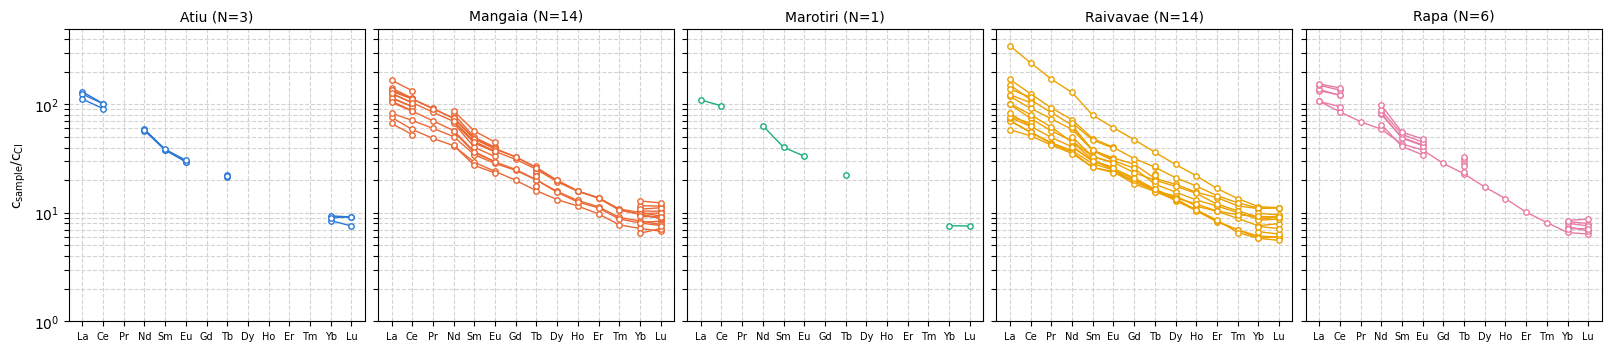

In [6]:
# (optional) plot the measured REE patterns
locations = sorted(data.location.unique())
fig, axs = plt.subplots(1, len(locations), figsize=(16, 3.4), sharey=True, layout="constrained")
for ax, loc, color in zip(axs, locations, COLORS):
    for _, row in data[data.location == loc].iterrows():
        plot_ree(ax, pd.to_numeric(row[REE], errors="coerce").to_numpy(dtype=float), color, 1)
    ax.set_title(f"{loc.split('(')[-1].rstrip(')')} (N={(data.location == loc).sum()})", fontsize=10)
    ax.set_ylim(1, 500)
    ax.tick_params(axis="x", labelsize=7)
for ax in axs[1:]:
    ax.set_ylabel("")
plt.show()

## 2. Olivine fractionation correction

The inversion compares the data with **primary-magma** compositions. Evolved basalts have crystallised olivine, which concentrates the REE in the remaining melt. `meltinv.correction` uses meltPT to add olivine back, step by step, until the melt is in equilibrium with mantle olivine of forsterite content `src_Fo` (default 0.9). The REE are then diluted by the added olivine: REE × (1 − `ol_added`).

The result is saved as `inversion_results/examples_corrected.xlsx`.

In [7]:
%%capture correction_log
# ▶ meltinv step 1: olivine fractionation correction
# (%%capture only hides meltPT's very long progress log; it is not needed in your own scripts)
meltinv.correction("examples.xlsx", src_Fo=0.9, max_olivine_addition=0.5)

In [8]:
# (optional) show the useful lines of the hidden log
show_log(correction_log)

Converted Excel file to CSV: examples.csv
Results saved to: inversion_results/examples_corrected.xlsx


The corrected file has three new kinds of column:

- `ol_added`: the mass fraction of olivine added;
- `correction_success`: `False` if meltPT could not correct a sample. Its REE are then set to missing, so it is not inverted with uncorrected values;
- `SiO2_primary` … `P2O5_primary`: the reconstructed primary major-element composition.

In [9]:
# (optional) read the corrected file: how much olivine was added at each location?
corrected = pd.read_excel("inversion_results/examples_corrected.xlsx")
print(f"Correction succeeded for {corrected.correction_success.sum()} of {len(corrected)} samples")
corrected.groupby("location").ol_added.describe()[["count", "min", "mean", "max"]].round(3)

Correction succeeded for 38 of 38 samples


,count,min,mean,max
location,,,,
Austral-Cook Islands (Atiu),3.0,0.070,0.117,0.164
Austral-Cook Islands (Mangaia),14.0,0.050,0.206,0.307
Austral-Cook Islands (Marotiri),1.0,0.200,0.200,0.200
Austral-Cook Islands (Raivavae),14.0,0.061,0.191,0.285
Austral-Cook Islands (Rapa),6.0,0.160,0.205,0.236


For one sample, the correction lowers every REE by the same factor, so the shape of the pattern does not change:

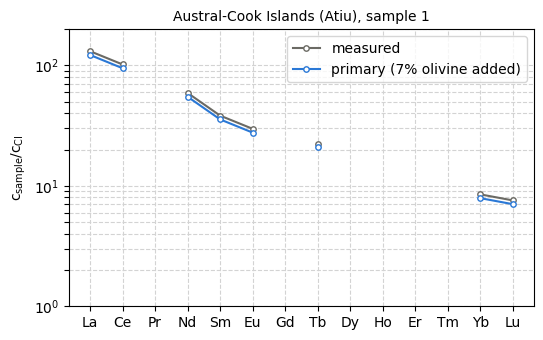

In [10]:
# (optional) plot one sample before and after the correction
i = 0
before = pd.to_numeric(data.loc[i, REE], errors="coerce").to_numpy(dtype=float)
after = corrected.loc[i, REE].to_numpy(dtype=float)
fig, ax = plt.subplots(figsize=(6, 3.6))
plot_ree(ax, before, "#6b6a64", 1.5, label="measured")
plot_ree(ax, after, "#2a78d6", 1.5, label=f"primary ({corrected.ol_added[i]:.0%} olivine added)")
ax.set_title(f"{data.location[i]}, sample 1", fontsize=10)
plt.show()

## 3. Run the inversion

`meltinv.invert` inverts **every sample individually** on a grid of mantle excess temperature (5 K steps), lithospheric thickness (2 km steps) and source enrichment (0–15% basalt in 0.1% steps). It reports the combination with the lowest misfit, then applies the pyroxenite T–P correction.

The file is already corrected, so `correction=False` (the default). We also ask for the individual figures, one per sample. Steps 1 and 2 can be combined into one call: `meltinv.invert("examples.xlsx", correction=True)`.

In [11]:
%%capture inversion_log
# ▶ meltinv step 2: invert every sample
# (%%capture only hides the long progress log)
meltinv.invert("inversion_results/examples_corrected.xlsx", individual_sample_figures=True)

In [12]:
# (optional) show the useful lines of the hidden log and count the figures
show_log(inversion_log, starts=("Results saved",))
print(f"\n{len(list(Path('inversion_figures').glob('*.png')))} figures saved in inversion_figures/")

Results saved to: inversion_results/examples_sample_inversion_log10.xlsx
Results saved to: inversion_results/examples_sample_inversion_summary_log10.xlsx

43 figures saved in inversion_figures/


Marotiri has only one sample. It is still inverted, appears in both results files and gets a group comparison figure; with fewer than 3 samples the figure shows the mean but no standard-deviation band.

**That is the whole analysis.** The rest of this notebook only reads the result files and figures that meltinv has written.

## 4. Read the results

### Per-sample results

`inversion_results/examples_sample_inversion_log10.xlsx` has one row per sample. The main columns are:

| Column | Meaning |
|---|---|
| `T_mean_cali` | mantle excess temperature (K), after the T–P correction |
| `depth_mean_cali` | lithospheric thickness (km), after the T–P correction |
| `basalt_percentage` | source enrichment: % of basalt mixed into primitive mantle |
| `misfit_value` | RMS log10 misfit, normalised by N − 3 (lower is better) |
| `T_mean`, `depth_mean` | the same before the T–P correction |

In [13]:
# (optional) read the per-sample results
samples = pd.read_excel("inversion_results/examples_sample_inversion_log10.xlsx")
cols = ["location", "sample_number", "T_mean_cali", "depth_mean_cali", "basalt_percentage", "misfit_value"]
samples[cols].head(8).round(3)

,location,sample_number,T_mean_cali,depth_mean_cali,basalt_percentage,misfit_value
0,Austral-Cook Islands (Atiu),1,70.648,64.072,5.2,0.038
1,Austral-Cook Islands (Atiu),2,68.208,59.368,4.5,0.049
2,Austral-Cook Islands (Atiu),3,75.841,55.269,2.9,0.025
3,Austral-Cook Islands (Mangaia),1,83.818,55.825,3.3,0.024
4,Austral-Cook Islands (Mangaia),2,96.718,55.653,1.9,0.013
5,Austral-Cook Islands (Mangaia),3,145.000,54.000,0.0,0.024
6,Austral-Cook Islands (Mangaia),4,47.623,65.029,11.0,0.041
7,Austral-Cook Islands (Mangaia),5,61.082,61.327,6.3,0.029


### Location summary

`inversion_results/examples_sample_inversion_summary_log10.xlsx` combines the samples at each location: every column is averaged over **all** samples, weighted by 1/misfit, so better-fitting samples count for more. The `_err_minus` and `_err_plus` columns give the weighted mean ± one weighted standard deviation.

In [14]:
# (optional) read the location summary
summary = pd.read_excel("inversion_results/examples_sample_inversion_summary_log10.xlsx")
cols = ["location", "count", "T_mean_cali", "T_mean_cali_err_minus", "T_mean_cali_err_plus",
        "depth_mean_cali", "basalt_percentage", "misfit_value", "litho_thickness_ref"]
summary[cols].round(2)

,location,count,T_mean_cali,T_mean_cali_err_minus,T_mean_cali_err_plus,depth_mean_cali,basalt_percentage,misfit_value,litho_thickness_ref
0,Austral-Cook Islands (Atiu),3,72.47,69.22,75.72,58.89,3.97,0.03,86.67
1,Austral-Cook Islands (Mangaia),14,102.47,74.86,130.09,57.88,2.58,0.02,83.45
2,Austral-Cook Islands (Marotiri),1,114.78,114.78,114.78,62.19,2.30,0.02,68.32
3,Austral-Cook Islands (Raivavae),14,114.30,61.77,166.84,62.81,2.98,0.03,73.77
4,Austral-Cook Islands (Rapa),6,170.92,146.03,195.82,91.56,4.66,0.03,67.93


## 5. Read the figures

All figures are saved in `inversion_figures/`.

### Group comparison figure (one per location, on by default)

This figure compares the samples at one location:

- **(a)–(c):** temperature, thickness and enrichment plotted against each other, one point per sample, coloured by misfit (darker blue = better fit);
- **(d-1)–(d-3):** histograms, with the misfit-weighted mean (dashed line) and ± 1 weighted standard deviation (grey band), as in the location summary.

The axes are fixed, so figures for different locations can be compared directly.

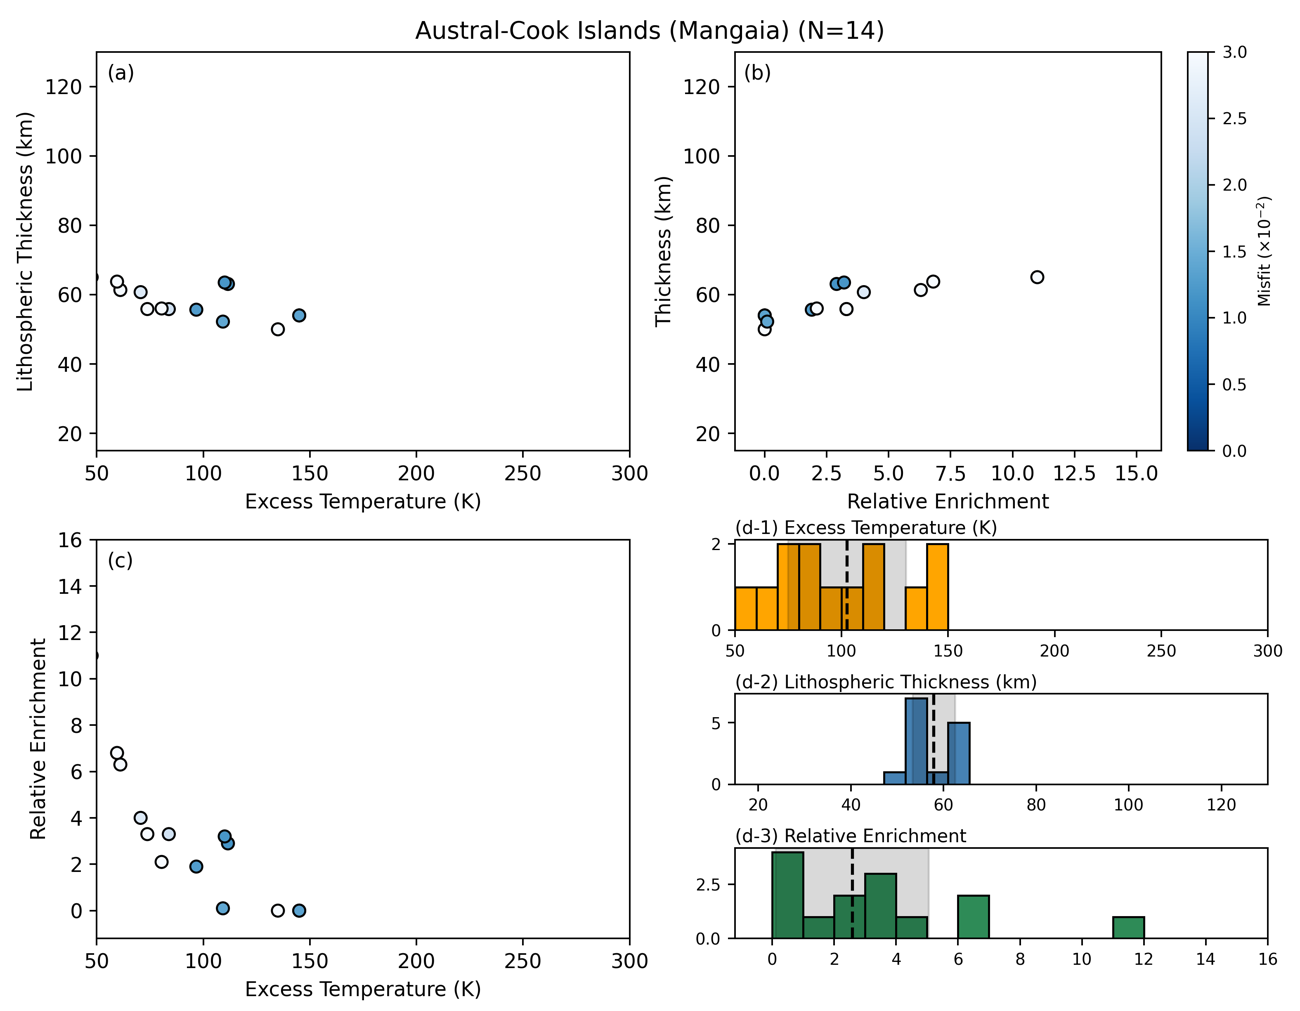

In [15]:
# (optional) show a saved group comparison figure
show_png("inversion_figures/group_comparison_Austral-Cook Islands (Mangaia)_N14.png")

### Individual figure (one per sample, with `individual_sample_figures=True`)

- **Top left:** the sample (black) against the best-fit model (red, with its uncertainty envelope) and the global best fit (orange);
- **Top right:** misfit across temperature and thickness at the best-fit enrichment, divided by the minimum misfit (so 1.1 means 10% worse than the best fit). The red star is the best fit; the dashed line is the seismic thickness;
- **Bottom:** the same misfit across temperature–enrichment and thickness–enrichment.

A long, narrow low-misfit valley, as in the top-right panel, shows that temperature and thickness trade off against each other.

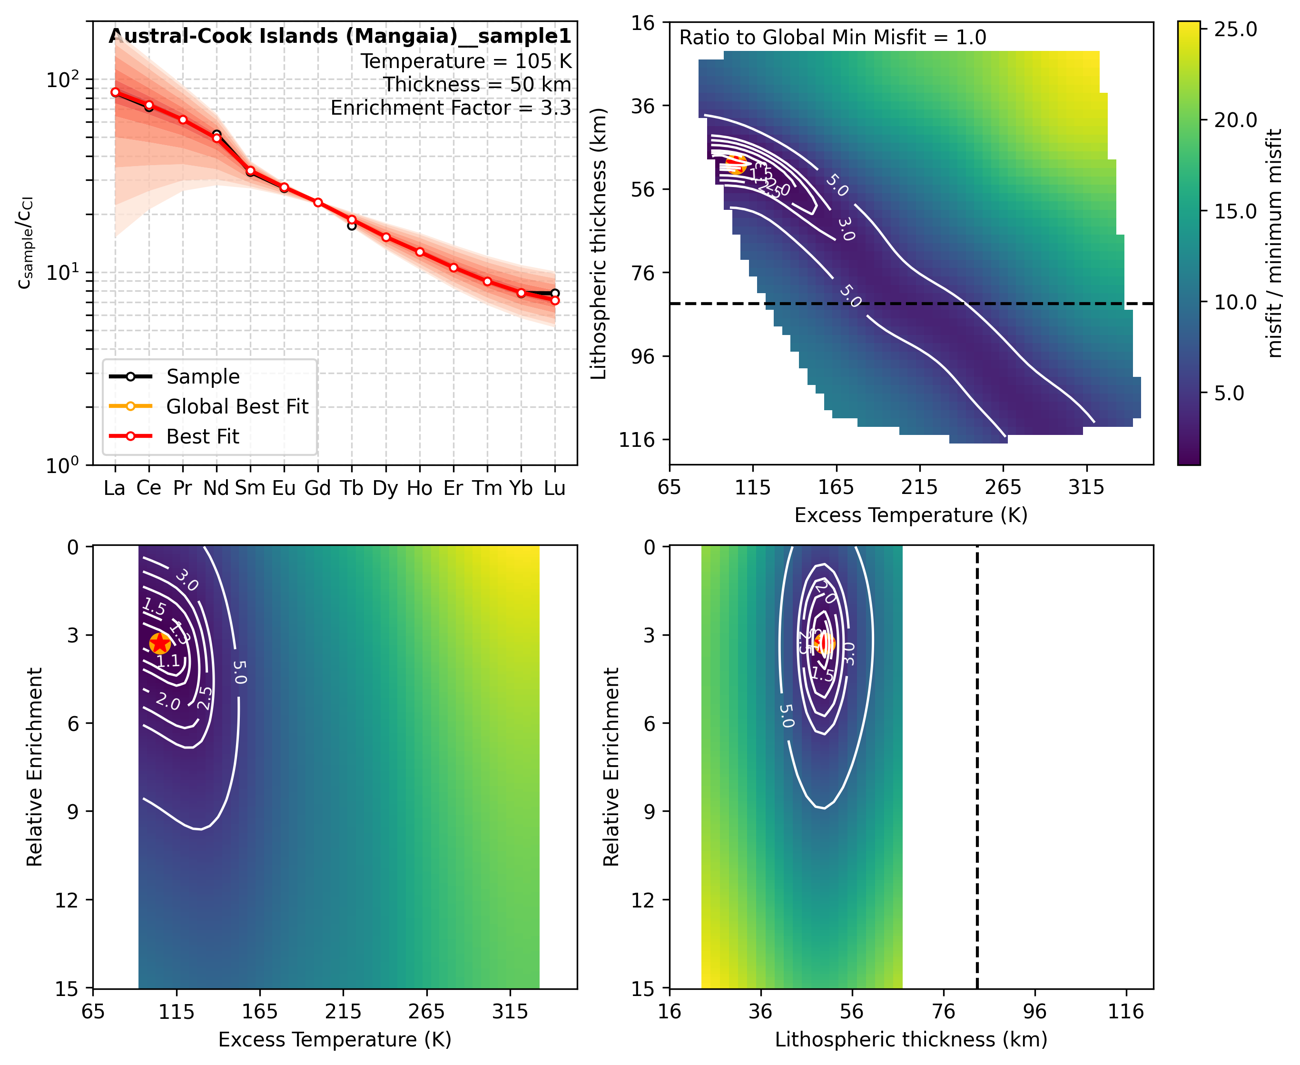

In [16]:
# (optional) show a saved individual figure
show_png("inversion_figures/ree_comparison_Austral-Cook Islands (Mangaia)__sample1_log10_N1.png")

## 6. Compare with seismic thickness

The example file has a `thickness` column with a seismic estimate of lithospheric thickness, reported as `litho_thickness_ref`. It is not used in the inversion, so it is an independent check. Here we keep locations with a misfit below 0.06 and compare the inverted thickness with and without the T–P correction.

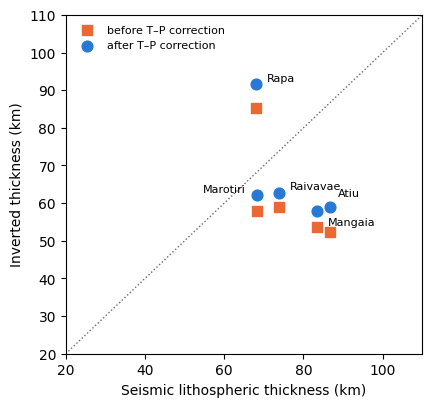

Mean |inverted - seismic| before the T–P correction: 21.4 km (5 locations)
Mean |inverted - seismic| after the T–P correction: 18.8 km (5 locations)


In [17]:
# (optional) plot inverted against seismic lithospheric thickness
good = summary[summary.misfit_value < 0.06]
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([20, 110], [20, 110], ":", color="#6b6a64", lw=1)
ax.scatter(good.litho_thickness_ref, good.depth_mean, s=60, marker="s", color="#eb6834", label="before T–P correction")
ax.scatter(good.litho_thickness_ref, good.depth_mean_cali, s=60, marker="o", color="#2a78d6", label="after T–P correction")
offsets = {"Atiu": (6, 8, "left"), "Mangaia": (8, -10, "left"), "Marotiri": (-8, 2, "right"),
           "Raivavae": (8, 2, "left"), "Rapa": (8, 2, "left")}          # keep the labels apart
for _, r in good.iterrows():
    name = r.location.split("(")[-1].rstrip(")")
    dx, dy, ha = offsets.get(name, (6, 4, "left"))
    ax.annotate(name, (r.litho_thickness_ref, r.depth_mean_cali), textcoords="offset points",
                xytext=(dx, dy), ha=ha, fontsize=8)
ax.set(xlabel="Seismic lithospheric thickness (km)", ylabel="Inverted thickness (km)", xlim=(20, 110), ylim=(20, 110))
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

for col, name in [("depth_mean", "before"), ("depth_mean_cali", "after")]:
    print(f"Mean |inverted - seismic| {name} the T–P correction: "
          f"{np.mean(np.abs(good[col] - good.litho_thickness_ref)):.1f} km ({len(good)} locations)")

With only five islands this is just an illustration. [Tutorial 2](02_modern_OIB.ipynb) makes the same comparison for 111 ocean-island locations.

## 7. The same analysis from the command line

The meltinv steps can also be run from a terminal, in the folder that contains `examples.xlsx`:

```bash
meltinv correction examples.xlsx
meltinv invert inversion_results/examples_corrected.xlsx --individual_sample_figures
```

or in one step:

```bash
meltinv invert examples.xlsx --correction --individual_sample_figures
```

## Next steps

- **[Tutorial 2](02_modern_OIB.ipynb):** the full modern ocean-island basalt dataset, ending with the comparison figure from the paper.
- The [README](../README.md) lists every argument, output file and output column.